---
# 实验5. 随机森林回归分析

**目标：**
- 掌握利用随机森林回归（RF）方法进行预测和分析。

**数据：**
- 三江源国家公园矢量边界数据（exercises/data/SanJiangYuan/map/boua.shp）；
- 2001-2020年三江源地区 NPP、气温和降水数据（exercises/data/SanJiangYuan）。其中，气温是每年4-10月间的月均温（℃），降水是每年4-10月间的总降水量（mm）。

**实验要求：**
- 利用随机的方法从研究区抽取一定数量的样本数据（例如5000个有效像元？），将其中的70%作为测试集（训练模型用），另外的30%用作验证集；
- 视NPP为因变量，气温和降水为自变量，构建起气温和降水与NPP间的RF模型；
- 利用验证数据集验证模型精度；
- 利用变量重要性（Variable Importance）度量方法确定降水和温度两个因子相对于NPP的重要性；
- 绘制降水和温度的偏依赖图（Partial Dependence），并做相应的分析。


1.用随机的方法从研究区抽取一定数量的样本数据（5000个有效像元），将其中的70%作为测试集（训练模型用），另外的30%用作验证集；视NPP为因变量，气温和降水为自变量，构建起气温和降水与NPP间的RF模型；利用验证数据集验证模型精度；

开始读取栅格数据并构建数据集...
全时段有效像元总数: 10348240
成功随机抽取 5000 个样本数据！
正在训练气温独立模型...
正在训练降水独立模型...

     气温与降水独立模型精度对比 (验证集)     
【气温模型】 决定系数 R²: 0.3801 | 均方根误差 RMSE: 0.0754
【降水模型】 决定系数 R²: 0.1371 | 均方根误差 RMSE: 0.0889


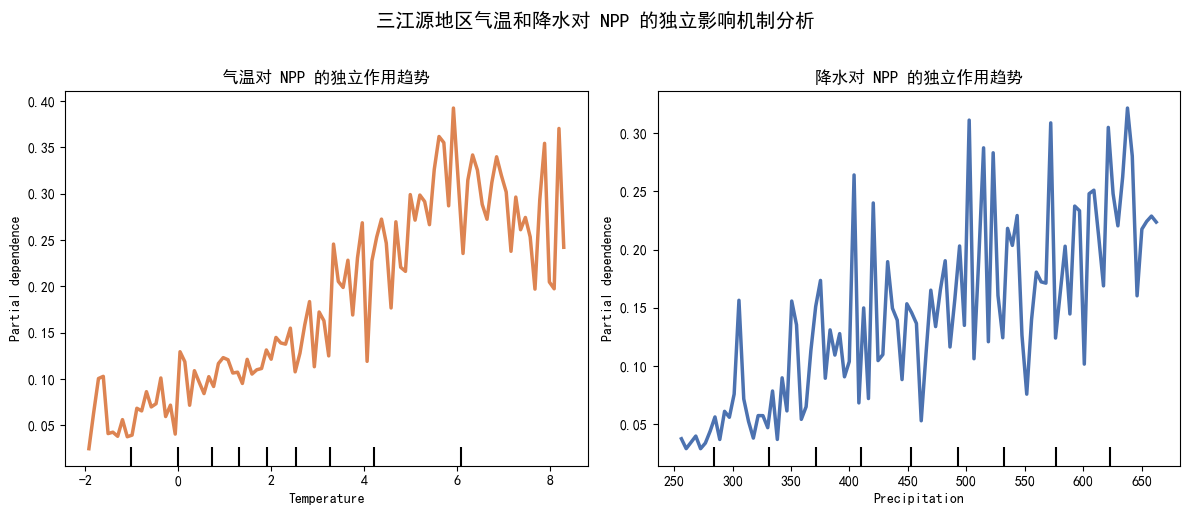

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio  # 用于读取地理栅格数据
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.inspection import PartialDependenceDisplay  # 用于绘制独立影响曲线

# ==========================================
# 1. 参数设置与路径定义
# ==========================================
BASE_DIR = "./data/SanJiangYuan"
TMP_DIR = os.path.join(BASE_DIR, "Temperature")
PRE_DIR = os.path.join(BASE_DIR, "Precipitation")
NPP_DIR = os.path.join(BASE_DIR, "NPP")

YEARS = range(2001, 2021) # 2001 到 2020 年
SAMPLE_SIZE = 5000         # 抽取样本数量
RANDOM_STATE = 42         # 随机种子，确保结果可复现

print("开始读取栅格数据并构建数据集...")

# ==========================================
# 2. 核心修复：循环读取 20 年的栅格数据，提取有效像元
# ==========================================
all_data_list = []

for year in YEARS:
    # 动态构建文件名
    tmp_path = os.path.join(TMP_DIR, f"tmp_{year}.tif")
    pre_path = os.path.join(PRE_DIR, f"pre_{year}.tif")
    npp_path = os.path.join(NPP_DIR, f"NPP_{year}.tif")
    
    # 检查文件是否存在
    if not (os.path.exists(tmp_path) and os.path.exists(pre_path) and os.path.exists(npp_path)):
        print(f"警告: {year} 年的数据文件不完整，已跳过。")
        continue
        
    # 读取栅格数据并展平为一维
    with rasterio.open(tmp_path) as src_tmp, \
         rasterio.open(pre_path) as src_pre, \
         rasterio.open(npp_path) as src_npp:
         
        tmp_band = src_tmp.read(1).flatten()
        pre_band = src_pre.read(1).flatten()
        npp_band = src_npp.read(1).flatten()
        
        # 过滤无效值 (NoData) 和 NaN 值
        valid_mask = (tmp_band != src_tmp.nodata) & \
                     (pre_band != src_pre.nodata) & \
                     (npp_band != src_npp.nodata) & \
                     (~np.isnan(tmp_band)) & (~np.isnan(pre_band)) & (~np.isnan(npp_band))
        
        # 提取当前年份的有效像元存入 DataFrame
        year_df = pd.DataFrame({
            'Temperature': tmp_band[valid_mask],
            'Precipitation': pre_band[valid_mask],
            'NPP': npp_band[valid_mask]
        })
        
        all_data_list.append(year_df)

# 合并全时段所有数据
full_dataset = pd.concat(all_data_list, ignore_index=True)
print(f"全时段有效像元总数: {len(full_dataset)}")

# ==========================================
# 3. 随机抽取 5000 个样本数据（定义 sampled_data）
# ==========================================
if len(full_dataset) < SAMPLE_SIZE:
    raise ValueError(f"有效像元总数不足 {SAMPLE_SIZE} 个，请减少 SAMPLE_SIZE 或检查数据路径。")

sampled_data = full_dataset.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)
print(f"成功随机抽取 {SAMPLE_SIZE} 个样本数据！")

# ==========================================
# 4. 数据集划分 (70% 训练, 30% 验证)
# ==========================================
# 为了确保对比公平，使用完全相同的样本划分索引
train_idx, val_idx = train_test_split(
    sampled_data.index, test_size=0.30, random_state=RANDOM_STATE
)

train_df = sampled_data.loc[train_idx]
val_df = sampled_data.loc[val_idx]

# =========================================================
# 5. 构建并训练【气温 -> NPP】独立模型
# =========================================================
print("正在训练气温独立模型...")
rf_tmp = RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)
rf_tmp.fit(train_df[['Temperature']], train_df['NPP'])

# 验证气温模型
pred_y_tmp = rf_tmp.predict(val_df[['Temperature']])
r2_tmp = r2_score(val_df['NPP'], pred_y_tmp)
rmse_tmp = np.sqrt(mean_squared_error(val_df['NPP'], pred_y_tmp))

# =========================================================
# 6. 构建并训练【降水 -> NPP】独立模型
# =========================================================
print("正在训练降水独立模型...")
rf_pre = RandomForestRegressor(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)
rf_pre.fit(train_df[['Precipitation']], train_df['NPP'])

# 验证降水模型
pred_y_pre = rf_pre.predict(val_df[['Precipitation']])
r2_pre = r2_score(val_df['NPP'], pred_y_pre)
rmse_pre = np.sqrt(mean_squared_error(val_df['NPP'], pred_y_pre))

# =========================================================
# 7. 对比两个模型的解释能力
# =========================================================
print("\n" + "="*40)
print("     气温与降水独立模型精度对比 (验证集)     ")
print("="*40)
print(f"【气温模型】 决定系数 R²: {r2_tmp:.4f} | 均方根误差 RMSE: {rmse_tmp:.4f}")
print(f"【降水模型】 决定系数 R²: {r2_pre:.4f} | 均方根误差 RMSE: {rmse_pre:.4f}")
print("="*40)

# =========================================================
# 8. 绘制部分依赖图 (Partial Dependence Plot)
# =========================================================
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 中文黑体
# plt.rcParams['font.sans-serif'] = ['Arial Unicode MS'] # 如果是Mac系统请取消本行注释，并把上一行加#
plt.rcParams['axes.unicode_minus'] = False

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=100)

# 绘制气温对NPP的影响曲线
PartialDependenceDisplay.from_estimator(
    rf_tmp, train_df[['Temperature']], features=['Temperature'], ax=ax1, 
    line_kw={"color": "#DD8452", "linewidth": 2.5}
)
ax1.set_title("气温对 NPP 的独立作用趋势", fontsize=12)
ax1.set_xlabel("4-10月月均温 (℃)")
ax1.set_ylabel("NPP 预测边际效应值")
ax1.grid(True, linestyle='--', alpha=0.5)

# 绘制降水对NPP的影响曲线
PartialDependenceDisplay.from_estimator(
    rf_pre, train_df[['Precipitation']], features=['Precipitation'], ax=ax2,
    line_kw={"color": "#4C72B0", "linewidth": 2.5}
)
ax2.set_title("降水对 NPP 的独立作用趋势", fontsize=12)
ax2.set_xlabel("4-10月总降水量 (mm)")
ax2.set_ylabel("NPP 预测边际效应值")
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("三江源地区气温和降水对 NPP 的独立影响机制分析", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

分析：以NPP为因变量，温度、降水为自变量构建随机森林模型，从模型决定系数和均方根误差来看，气温模型的拟合效果更好。由结果可以看出，气温在4-6℃时对NPP的作用最显著，降水量在400-450和500-550这个区间里对NPP有很大作用。

2.利用变量重要性（Variable Importance）度量方法确定降水和温度两个因子相对于NPP的重要性

正在训练多变量随机森林模型...
模型训练完成！

       变量重要性评估结果       
4-10月月均温 (Temperature)         : 0.5981
4-10月总降水量 (Precipitation)      : 0.4019


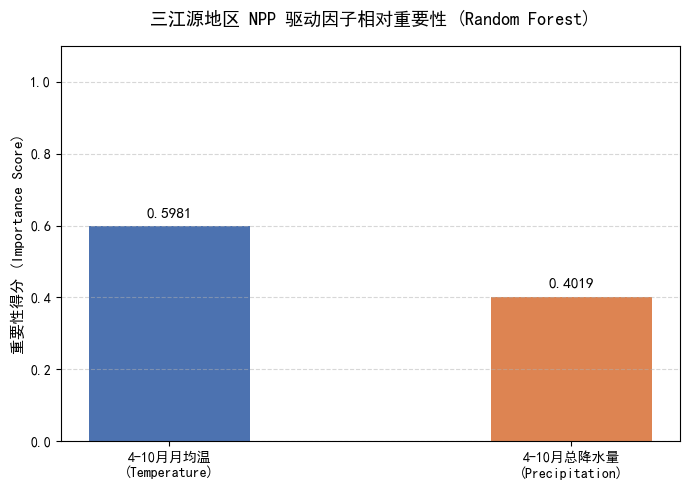

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor

# ==========================================
# 1. 构建包含双自变量的随机森林模型
# ==========================================
print("正在训练多变量随机森林模型...")
# 视 NPP 为因变量，气温和降水为自变量
X_train = train_df[['Temperature', 'Precipitation']]
y_train = train_df['NPP']
X_val = val_df[['Temperature', 'Precipitation']]
y_val = val_df['NPP']

# 初始化并训练模型
rf_joint = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)
rf_joint.fit(X_train, y_train)
print("模型训练完成！")

# ==========================================
# 2. 提取并归一化变量重要性得分
# ==========================================
importances = rf_joint.feature_importances_
feature_names = X_train.columns

# 转为 DataFrame 方便处理
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("\n" + "="*30)
print("       变量重要性评估结果       ")
print("="*30)
for index, row in importance_df.iterrows():
    # 翻译成中文显示在控制台
    name_cn = "4-10月总降水量 (Precipitation)" if row['Feature'] == 'Precipitation' else "4-10月月均温 (Temperature)"
    print(f"{name_cn:<30} : {row['Importance']:.4f}")
print("="*30)

# ==========================================
# 3. 绘制变量重要性条形图（解决中文乱码）
# ==========================================
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 黑体
# plt.rcParams['font.sans-serif'] = ['Arial Unicode MS'] # Mac 用户请取消本行注释
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(7, 5), dpi=100)
colors = ['#4C72B0', '#DD8452']  # 为两个因子配置对比色

# 映射特征名称为中文供图表使用
importance_df['Feature_CN'] = importance_df['Feature'].map({
    'Precipitation': '4-10月总降水量\n(Precipitation)',
    'Temperature': '4-10月月均温\n(Temperature)'
})

bars = plt.bar(importance_df['Feature_CN'], importance_df['Importance'], color=colors, width=0.4)

# 在条形图上方标注具体数字
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('三江源地区 NPP 驱动因子相对重要性 (Random Forest)', fontsize=13, pad=15)
plt.ylabel('重要性得分 (Importance Score)', fontsize=11)
plt.ylim(0, 1.1)  # 保证上方数字不被遮挡
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

分析：温度相较于降水对NPP的驱动力更大，也就是NPP受温度的影响更大

3.绘制降水和温度的偏依赖图（Partial Dependence），并做相应的分析

正在计算并绘制偏依赖图，请稍候...


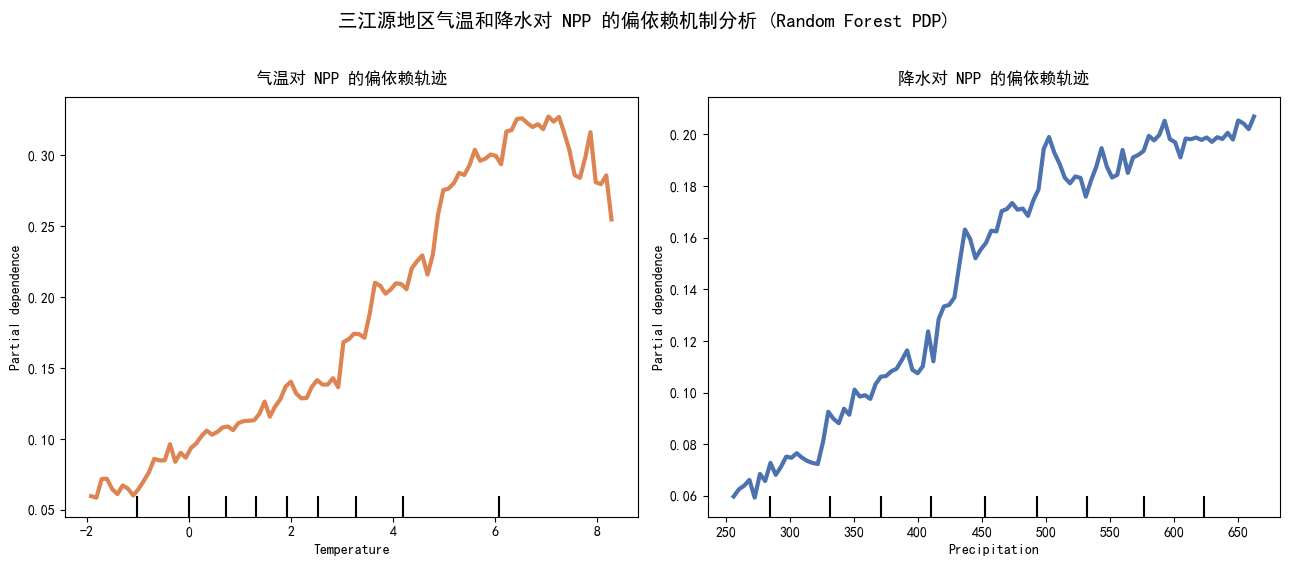

In [8]:
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

# =========================================================
# 1. 绘图基础配置（解决中文乱码）
# =========================================================
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 中文黑体
# plt.rcParams['font.sans-serif'] = ['Arial Unicode MS'] # 如果是Mac系统请取消本行注释
plt.rcParams['axes.unicode_minus'] = False

# =========================================================
# 2. 绘制多变量模型中各因子的偏依赖图 (PDP)
# =========================================================
# 创建 1 行 2 列的画布
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), dpi=100)

print("正在计算并绘制偏依赖图，请稍候...")

# 绘制气温的偏依赖图
PartialDependenceDisplay.from_estimator(
    estimator=rf_joint,          # 使用训练好的双变量随机森林模型
    X=X_train,                   # 训练集特征数据
    features=['Temperature'],    # 指定要分析的特征
    ax=ax1,                      # 指定画在左边子图
    line_kw={"color": "#DD8452", "linewidth": 3} # 设定线条颜色和粗细
)
ax1.set_title("气温对 NPP 的偏依赖轨迹", fontsize=12, pad=10)
ax1.set_xlabel("4-10月月均温 (℃)", fontsize=11)
ax1.set_ylabel("NPP 预测偏依赖值 (边际效应)", fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)

# 绘制降水的偏依赖图
PartialDependenceDisplay.from_estimator(
    estimator=rf_joint,
    X=X_train,
    features=['Precipitation'],
    ax=ax2,                      # 指定画在右边子图
    line_kw={"color": "#4C72B0", "linewidth": 3}
)
ax2.set_title("降水对 NPP 的偏依赖轨迹", fontsize=12, pad=10)
ax2.set_xlabel("4-10月总降水量 (mm)", fontsize=11)
ax2.set_ylabel("NPP 预测偏依赖值 (边际效应)", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)

# 整体大标题
plt.suptitle("三江源地区气温和降水对 NPP 的偏依赖机制分析 (Random Forest PDP)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

分析：温度在4-8℃时对NPP的作用最强，降水量在500-550这个区间时对NPP的作用最强，且降水对NPP的影响随降水量增加而增大